# EEE4022S Thesis Project: The development of a low-cost X-ray phantom for bone suppression and radiography system calibration

## By: M Saeed Solomon (SLMMOG032)

In [7]:
# Import libraries
import numpy as np
import pydicom
import os
import matplotlib.pyplot as plt
from scipy.ndimage import affine_transform
from scipy.optimize import minimize

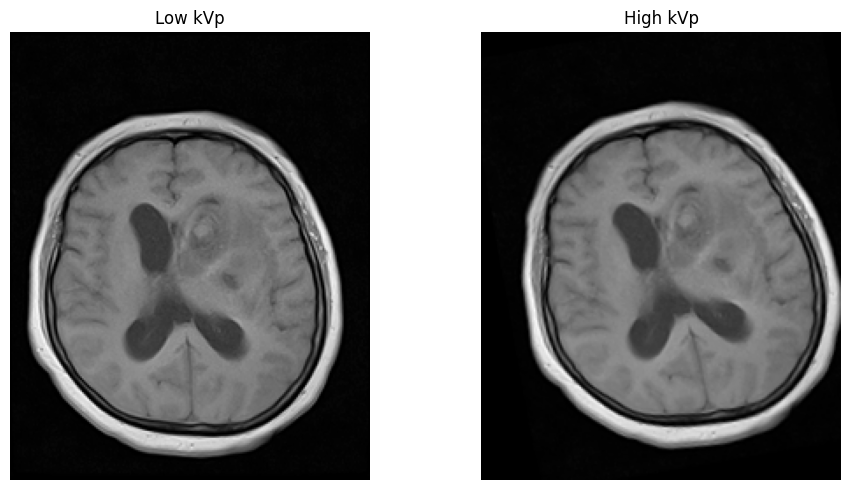

In [4]:
# ========================================================================================================

# Phase 1: Import Images

image_1 = pydicom.dcmread('./Images/1.dcm')
image_2 = pydicom.dcmread('./Images/2.dcm')  

# Function to repeat reading in and normalizing image
def ready_img(image):
    data_set = image.pixel_array.astype(float)
    if data_set.ndim == 3:
        data_set = data_set[..., 0]  # to ensure the image dimensions are only 2D
    return (data_set - data_set.min()) / (data_set.max() - data_set.min())

target = ready_img(image_1)
misaligned = ready_img(image_2)


# Display initial images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(target, cmap="gray")
axes[0].set_title("Low kVp")
axes[1].imshow(misaligned, cmap="gray")
axes[1].set_title("High kVp")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

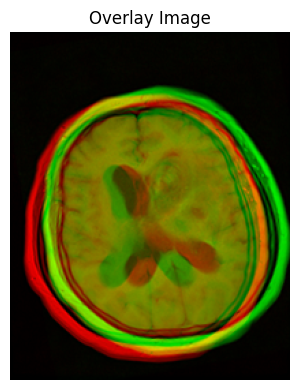

Optimal parameters: 
theta=-10.00 degrees 
tx=10.08 pixels 
ty=-5.09 pixels

Affine transformation matrix:
[[ 0.98479811  0.17370286 10.07695783]
 [-0.17370286  0.98479811 -5.09462122]
 [ 0.          0.          1.        ]]


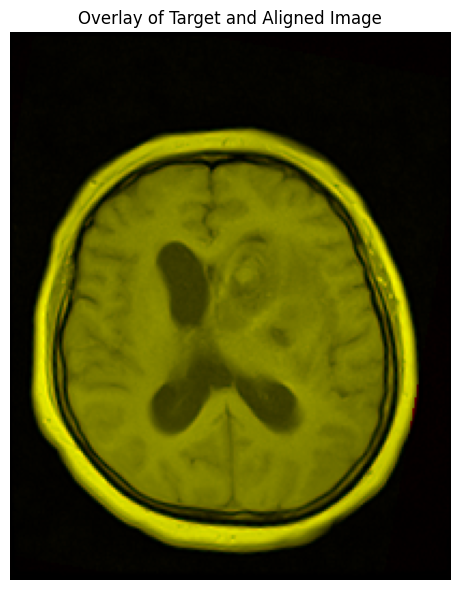

In [ ]:
# ========================================================================================================

# Phase 2: Pre-processing

"""Despite the aim of thesis being to use the developed phantom for bone suppression, one cannot simply assume the phantom will not move
between subsequent scans. This could be due to the phantom being manually moved, slight shifts caused by bumping into the scanner or simply
as a result of the scanner's vibrations. Therefore it is important to align the images before any further processing. This is done by 
finding the optimal transformation parameters that minimize the mean squared error (MSE) between the target and misaligned images."""

# Get rgb overlay
overlay = rgb = np.stack([target, misaligned, np.zeros_like(target)], axis=-1)

# Show overlayed image
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(overlay)
ax.set_title('Overlay Image')
ax.axis('off')
plt.tight_layout()
plt.show()

# Define 'fun' function that is applied in minimize function
# As mentioned in instructions, mse will be used as the similarity metric to be minimized

H, W = target.shape

def transformation(image, theta, tx, ty):
    theta_rad = np.deg2rad(theta)
    cos_t, sin_t = np.cos(theta_rad), np.sin(theta_rad)
    cy, cx = H / 2, W / 2           # so that center of image is the pivot point for rotation

    # Rotational matrix
    R = np.array([[cos_t,  sin_t],
                  [-sin_t, cos_t]])
    
    # Offset to ensure rotation around the center and translation
    offset = np.array([cy, cx]) - R @ np.array([cy, cx]) + np.array([ty, tx])

    return affine_transform(image, R, offset=offset, order=1, mode='constant', cval=0)  # Return affine matrix transformation of the image

def mse(params):
    theta, tx, ty = params              # Retrieve parameters
    warped = transformation(misaligned, theta, tx, ty)      # Perform transformation
    return np.mean((target - warped) ** 2)

# Use optimization
x0 = [0, 0, 0]                      # initial guess for [theta, tx, ty]
result = minimize(mse, x0, method='Powell')     # mse continuously called internally until optimized parameters are found

# Extract optimal parameters
theta_opt, tx_opt, ty_opt = result.x
print(f"Optimal parameters: \ntheta={theta_opt:.2f} degrees \ntx={tx_opt:.2f} pixels \nty={ty_opt:.2f} pixels") # for displaying the results
print()

# Get affine transformation matrix
theta_rad = np.deg2rad(theta_opt)
cos_theta, sin_theta = np.cos(theta_rad), np.sin(theta_rad)
affine_matrix = np.array([[cos_theta, -sin_theta, tx_opt],
                          [sin_theta,  cos_theta, ty_opt],
                          [0,          0,         1]])

print("Affine transformation matrix:")
print(affine_matrix)

# Apply transformation to misaligned image
# Function transformation defined in part (b) is used here to apply the optimal transformation to the misaligned image
aligned_image = transformation(misaligned, theta_opt, tx_opt, ty_opt)

# Show overlay of aligned image
overlay_aligned = np.stack([target, aligned_image, np.zeros_like(target)], axis=-1)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(overlay_aligned)
ax.set_title('Overlay of Target and Aligned Image')
ax.axis('off')
plt.tight_layout()
plt.show()